# Basic LCOH Calculator

In [84]:
#inputs, defining terms

capacity_mw = 10 #electrolyzer capacity
capex_per_kw = 1000 #installed cost in usd
electricity_cost = 0.06 #usd per kwh
efficiency_kwh_per_kg = 52 #electricity needed in kwh for kg of H2
capacity_factor = 0.90 #fraction of the year that the plant runs
opex_fraction = 0.03 #yearly operation and maintenance as a fraction of capex
lifetime_years = 20
discount_rate = 0.1 #10% per year

In [85]:
print(capacity_mw, lifetime_years, discount_rate)

10 20 0.1


In [86]:
#Annual hydrogen production
capacity_in_kw = capacity_mw * 1000
hours_per_year = 8760
annual_energy_consumed = capacity_in_kw * hours_per_year * capacity_factor
annual_H2_in_kg = annual_energy_consumed/efficiency_kwh_per_kg
print(f"Annual electricity used is: {annual_energy_consumed:,.0f} kwh")
print(f"Amound of hydrogen produced per year is: {annual_H2_in_kg:,.0f} kg")

Annual electricity used is: 78,840,000 kwh
Amound of hydrogen produced per year is: 1,516,154 kg


In [87]:
#Annual upfront cost
capex = capex_per_kw * capacity_in_kw #one time cost
annual_electricity_cost = electricity_cost * annual_energy_consumed
annual_OM_cost = capex * opex_fraction
annual_opex = annual_electricity_cost + annual_OM_cost
print(f"CAPEX is: {capex:,.0f} USD")
print(f"Electricity cost per year is: {annual_electricity_cost:,.0f} USD")
print(f"Annual O&M cost is {annual_OM_cost:,.0f} USD")
print(f"Annual OPEX is {annual_opex:,.0f} USD")

CAPEX is: 10,000,000 USD
Electricity cost per year is: 4,730,400 USD
Annual O&M cost is 300,000 USD
Annual OPEX is 5,030,400 USD


In [88]:
#Discounted costs and hydrogen, year by year
presentValue_cost = capex 
presentValue_H2_cost = 0

for years in range(1, lifetime_years + 1):
    discount_factor = 1/(1 + discount_rate)** years
    presentValue_cost += annual_opex * discount_factor
    presentValue_H2_cost += annual_H2_in_kg * discount_factor

lcoh = presentValue_cost/presentValue_H2_cost
print(f"Present value total cost is: {presentValue_cost:,.0f} USD")
print(f"Present value of total hydrogen is: {presentValue_H2_cost:,.0f} kg")
print(f"LCOH is: {lcoh:,.3f} per kg of hydrogen")

Present value total cost is: 52,826,631 USD
Present value of total hydrogen is: 12,907,872 kg
LCOH is: 4.093 per kg of hydrogen


In [89]:
# Cross-checking using the annuity factor

annuity_factor = (1 - (1 + discount_rate) ** -lifetime_years) / discount_rate
lcoh_check = (capex + annual_opex * annuity_factor) / (annual_H2_in_kg * annuity_factor)

print(f"Annuity factor: {annuity_factor:.4f}")
print(f"LCOH (check): ${lcoh_check:.3f} per kg of H2")

Annuity factor: 8.5136
LCOH (check): $4.093 per kg of H2


In [90]:
#Stack replacement
stack_replacement_year = 10
fraction_cost_of_stack = 0.35 #fraction of original CAPEX

In [91]:
replacement_cost = fraction_cost_of_stack * capex

presentValue = capex
presentValue_H2_cost = 0

for years in range(1, lifetime_years + 1):
    discount_factor = 1/(1 + discount_rate)** years

    yearly_cost = annual_opex
    if years == stack_replacement_year:
        yearly_cost += replacement_cost #extra cost calculated in the 10th year

    presentValue += yearly_cost * discount_factor
    presentValue_H2_cost += annual_H2_in_kg * discount_factor

lcoh_with_stack_rep = presentValue/presentValue_H2_cost

print(f"Replacement cost is: {replacement_cost:,.0f} in USD")
print(f"LCOH with stack replacement is {lcoh_with_stack_rep:,.3f} per kg")

Replacement cost is: 3,500,000 in USD
LCOH with stack replacement is 4.197 per kg


In [111]:
#LCOH using real values in Kenyan context
def calculate_lcoh(
    capacity_mw = 10,
    capex_per_kw = 2100, #alkaline installed cost, USD/kW (EH2 whitepaper, 2024)
    electricity_cost = 0.07, #USD/kWh generation-level price, Kenyan geothermal tariff cap ~KES 9 (ThinkGeoEnergy)
    efficiency_kwh_per_kg = 58, #plant-level incl. compression to 30 bar (EH2 whitepaper)
    capacity_factor = 0.90, 
    opex_fraction = 0.026, #fixed O&M as fraction of CAPEX, alkaline (EH2 whitepaper)
    lifetime_years = 20,  
    discount_rate = 0.13, #Kenya hydrogen WACC (GIZ Kenya sector analysis, 2025)
    stack_replacement_year = 10, #alkaline stack life up to 10 years (EH2 whitepaper)
    fraction_cost_of_stack = 0.15 #stack replacement as fraction of CAPEX, alkaline (EH2)
):
    """Levilized cost of hydrogen in (USD/kg) for geothermal-powered alkaline electrolyzer."""
    capacity_in_kw = capacity_mw * 1000
    annual_energy_consumed = capacity_in_kw * 8760 * capacity_factor
    annual_H2_in_kg = annual_energy_consumed/efficiency_kwh_per_kg

    capex = capacity_in_kw * capex_per_kw
    annual_opex = annual_energy_consumed * electricity_cost + capex * opex_fraction 
    replacement_cost = capex * fraction_cost_of_stack

    presentValue = capex
    presentValue_H2_cost = 0

    for years in range(1, lifetime_years + 1):
        discount_factor = 1/(1+discount_rate) ** years
        yearly_cost = annual_opex
        if years == stack_replacement_year:
            yearly_cost += replacement_cost

        presentValue += yearly_cost * discount_factor
        presentValue_H2_cost += annual_H2_in_kg * discount_factor

    return presentValue/presentValue_H2_cost 



In [113]:
print(f"Base case LCOH(Kenya, geothermal, 10MW alkaline): ${calculate_lcoh():.2f} per kg H2")

Base case LCOH(Kenya, geothermal, 10MW alkaline): $6.76 per kg H2


In [115]:
#geothermal, solar and wind comparison
for name, cf in [("solar = (30%)", 0.3), ("wind = (45%)", 0.45), ("geothermal = (90%)", 0.9)]:
    print(f"{name}: ${calculate_lcoh(capacity_factor = cf):.3f} per kg")

solar = (30%): $12.154 per kg
wind = (45%): $9.456 per kg
geothermal = (90%): $6.758 per kg


In [117]:
#sensitivity analysis
base_lcoh = calculate_lcoh()

ranges = {
    "capex_per_kw": (1900, 3000),
    "electricity_cost": (0.06, 0.10),
    "efficiency_kwh_per_kg": (50, 60),
    "capacity_factor": (0.85, 0.93),
    "opex_fraction": (0.015, 0.03),
    "lifetime_years": (15, 25),
    "fraction_cost_of_stack": (0.15, 0.20),
    "discount_rate": (0.085, 0.15),
    "stack_replacement_year": (7, 14),
}

results = []

for name, (low, high) in ranges.items():
    lcoh_low = calculate_lcoh(**{name: low})
    lcoh_high = calculate_lcoh(**{name: high})
    swing = abs(lcoh_high - lcoh_low)
    results.append((name, lcoh_low, lcoh_high, swing))

results.sort(key=lambda r:r[3], reverse=True)

print(f"Base LCOH: ${base_lcoh:.2f}\n")
for name, low, high, swing in results:
    print(f"{name:24s} low:${low:.2f} high:${high:.2f} swing:${swing:.2f}")

Base LCOH: $6.76

electricity_cost         low:$6.18 high:$8.50 swing:$2.32
capex_per_kw             low:$6.50 high:$7.91 swing:$1.41
efficiency_kwh_per_kg    low:$5.83 high:$6.99 swing:$1.17
discount_rate            low:$6.20 high:$7.02 swing:$0.82
lifetime_years           low:$6.96 high:$6.66 swing:$0.30
capacity_factor          low:$6.92 high:$6.67 swing:$0.25
opex_fraction            low:$6.59 high:$6.82 swing:$0.23
stack_replacement_year   low:$6.80 high:$6.72 swing:$0.08
fraction_cost_of_stack   low:$6.76 high:$6.79 swing:$0.03


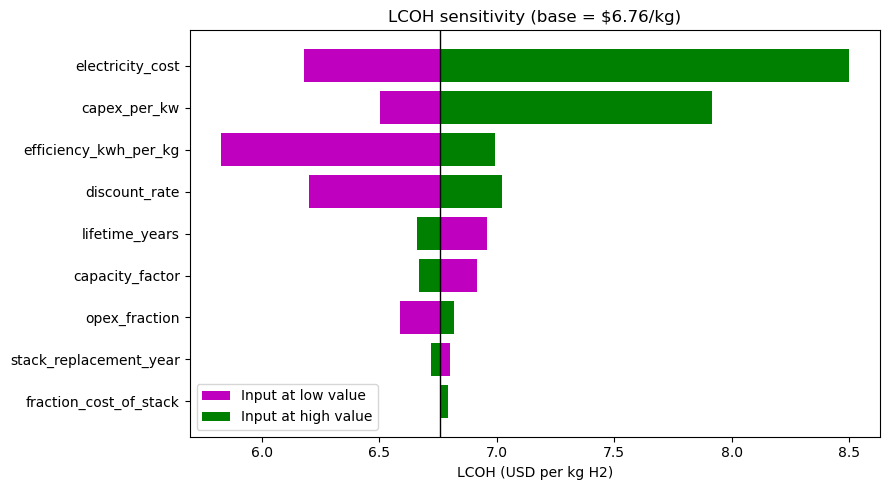

In [119]:
#visualization in tornado chart

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9,5))

for i, (name, low, high, swing) in enumerate(reversed(results)):
    ax.barh(i, low - base_lcoh, left=base_lcoh, color="m",
            label="Input at low value" if i == 0 else None)
    ax.barh(i, high - base_lcoh, left=base_lcoh, color="g",
            label="Input at high value" if i == 0 else None)

ax.set_yticks(range(len(results)))
ax.set_yticklabels([r[0] for r in reversed(results)])
ax.axvline(base_lcoh, color="black", linewidth=1)
ax.set_xlabel("LCOH (USD per kg H2)")
ax.set_title(f"LCOH sensitivity (base = ${base_lcoh:.2f}/kg)")
ax.legend()
plt.tight_layout()
plt.savefig("tornado_chart.png", dpi=150)
plt.show()
    

In [129]:
import numpy as np
rng = np.random.default_rng(42) #fixed seed
n_runs = 5000 
distributions = {
    "electricity_cost":     (0.06, 0.07, 0.10),
    "capex_per_kw":          (1900, 2100, 3000),
    "efficiency_kwh_per_kg": (50, 58, 60),
    "discount_rate":         (0.085, 0.13, 0.15),
    "opex_fraction":         (0.015, 0.026, 0.03),
    "capacity_factor":       (0.85, 0.90, 0.93),
    "fraction_cost_of_stack":   (0.15, 0.15, 0.20),
}

samples = {name: rng.triangular(low, mode, high, n_runs) #5000 random values for each input
    for name, (low, mode, high) in distributions.items()}

#run the model once per draw
lcoh_results = np.array([
    calculate_lcoh(**{name: samples[name][i] for name in distributions})
    for i in range(n_runs)
])

p5, p50, p95 = np.percentile(lcoh_results, [5, 50, 95])
print(f"Mean LCOH: ${lcoh_results.mean():.2f} per kg")
print(f"Median LCOH: ${p50:.2f} per kg")
print(f"5th to 95th percentile: ${p5:.2f} to ${p95:.2f} per kg")

Mean LCOH: $7.07 per kg
Median LCOH: $7.01 per kg
5th to 95th percentile: $6.06 to $8.23 per kg


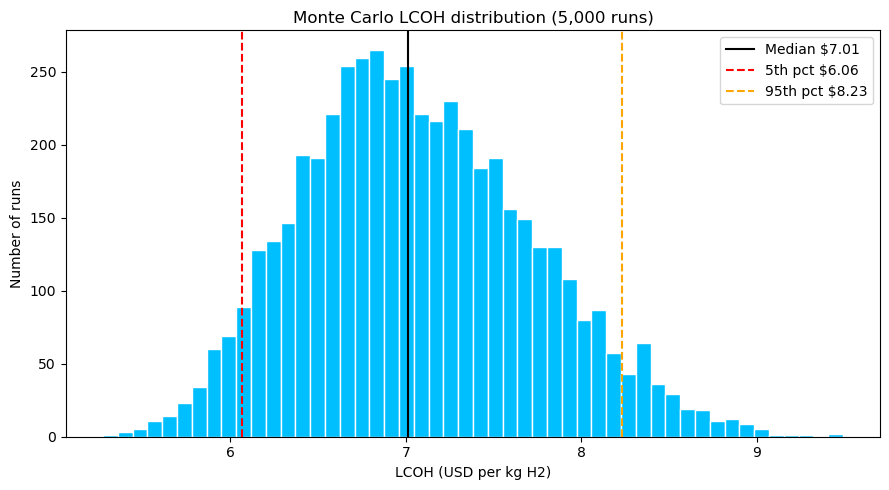

In [165]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(lcoh_results, bins=50, color="deepskyblue", edgecolor="white")
ax.axvline(p50, color="k", linewidth=1.5, label=f"Median ${p50:.2f}")
ax.axvline(p5, color="r", linestyle="--", label=f"5th pct ${p5:.2f}")
ax.axvline(p95, color="orange", linestyle="--", label=f"95th pct ${p95:.2f}")
ax.set_xlabel("LCOH (USD per kg H2)")
ax.set_ylabel("Number of runs")
ax.set_title("Monte Carlo LCOH distribution (5,000 runs)")
ax.legend()
plt.tight_layout()
plt.savefig("monte_carlo_distribution.png", dpi=150)
plt.show()

In [171]:
print("Correlation of each input with LCOH")
for name in distributions:
    r = np.corrcoef(samples[name], lcoh_results)[0,1]
    print(f" {name:24s} {r:+.2f}")

Correlation of each input with LCOH
 electricity_cost         +0.74
 capex_per_kw             +0.44
 efficiency_kwh_per_kg    +0.43
 discount_rate            +0.28
 opex_fraction            +0.06
 capacity_factor          -0.09
 fraction_cost_of_stack   +0.04
